# Each TS trains their own alpha, using their own scores

In [5]:
from astropy.io import fits

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy import stats as ss
from scipy.io import readsav
from sklearn.decomposition import PCA

from tqdm import tqdm

import tools as t

## Load data

In [6]:
# load files
path_data = '../data/sim_series/'  # directory where the files are saved
N_files = 20  # 20 temporal series (from 0 to 19)
data_spectra = []
data_rv = []
for i in range(N_files):  # files have the same name, only number changes
    data_spectra.append(fits.getdata(path_data + f'flux_norm_6173_lionel_tau1_spatialscaling1_sansrotation_serie{i}.fits'))
    data_rv.append(readsav(path_data + f'res_rv_bis_6173_lionel_tau1_scaling1_sansrot_serie{i}.sav'))
data_spectra = np.array(data_spectra)
data_rv = np.array(data_rv)
print(data_rv[0].keys())

dict_keys(['rv_gauss', 'rv_correl', 'rv_deriv', 'xbiss', 'ybiss', 'l_true', 'lambd', 'flux_moy'])


In [7]:
c = 3e8  # speed of light [m/s]
# extract data
wl = np.array(data_rv[0]['lambd'])  # same wavelength grid for all time series (verified)
times = np.arange(0, len(data_spectra[0]) * 144, 144) / 60 / 24  # time in days, same for all time series
times_sec = times * 86400  # time in sec
# extract RV data
wl = np.array(wl)

## Preprocessing

In [8]:
# preprocessing all TS
mean_spec = np.array([np.mean(i, axis=0) for i in data_spectra])  # list of mean spectrum for each TS
d_S0 = np.array([np.gradient(i, wl) for i in mean_spec])  # list of derivative of the mean spectra for each TS

S_f = []  # array of matrices
D_vectors = []  # array of Doppler vectors

for i in range(N_files):  # for each TS
    s, v = t.subtract_D(wl, data_spectra[i], c=c)  # take out projection over the Doppler vector
    S_f.append(s)
    D_vectors.append(v)

S_f = np.array(S_f)
D_vectors = np.array(D_vectors)

spectra_centered = np.array([t.double_centering(i) for i in S_f])

## Calculate RV by template matching

In [10]:
# calculate RV for all the TS
C_0 = 1000
rv_tm = []  # list of RV vector for each TS
for j in range(N_files):  # for each TS
    rv_j = []
    for k in range(len(times)):  # for each spectrum
        rv_j.append(t.calculate_rv(wl, mean_spec[j], data_spectra[j][k], C_0))  # calculate RV by TM
    rv_tm.append(np.array(rv_j))
rv_tm = np.array(rv_tm)

## PCA

In [11]:
# apply PCA to the centered matrix
n_components = 16

pcs_ts = []  # list of N_files lists of of principal components
loadings_ts = []  # list of loadings of all PCs for each TS
scores_ts = []  # list of scores of all PCs for each TS
var_ts = []  # list of PC variance for each TS

for i in spectra_centered:  # each i is a double-centered matrix (corresponding to each TS)
    pca_flux_i = PCA(n_components=n_components)  # create PCA object
    pcs_i = pca_flux_i.fit_transform(i)  # fit the model with spectra_centered and apply the dimensionality reduction
    pcs_ts.append(pcs_i)  # save PCs
    loadings_ts.append(pca_flux_i.components_)  # save loadings
    scores_ts.append(np.array([pcs_i[:, j] for j in range(n_components)]))  # save scores
    var_ts.append(pca_flux_i.explained_variance_ratio_)  # save PC variation

pcs_ts = np.array(pcs_ts)
loadings_ts = np.array(loadings_ts)
scores_ts = np.array(scores_ts)
var_ts = np.array(var_ts)

## Linear model

In [12]:
scores_ts.shape

(20, 16, 3686)

In [18]:
# train-test split
N = len(times)
train_size = int(.7 * N)

scores_train = np.array([i[:, :train_size] for i in scores_ts])
rv_true_train = np.array([i[:train_size] for i in rv_tm])
times_train = times[:train_size]

scores_test = np.array([i[:, train_size:] for i in scores_ts])
rv_true_test = np.array([i[train_size:] for i in rv_tm])
times_test = times[train_size:]

In [19]:
# training the model
# chunks are not necessary, as using them would give the exact same result for alpha

alpha_ts = []
for i in range(N_files):
    I_train = scores_train[i].T

    G = np.dot(I_train.T, I_train)
    b = np.dot(I_train.T, rv_true_train[i])
    alpha_ts.append(np.linalg.solve(G, b))

In [20]:
# use alpha to test by chunks
chunk_size = 21
test_size = N - train_size

rv_pred_test = []  # predicted RV in chunks
res = []           # residuals in chunks
res_sigma = []     # std of the residuals by chunk

for i in range(N_files):

    I_test_i = scores_test[i].T
    rv_true_i = rv_true_test[i]

    rv_pred_i = []    # list of chunks of predicted RV
    res_i = []        # list of chunks of residuals calculated from rv_pred_i
    res_sigma_i = []  # list of numbers: std of each chunk in res_i

    j = 0

    while j < test_size:
        
        if j + chunk_size > test_size:
            break

        else:
            I_test_j = I_test_i[j:j+chunk_size]  # pseudo-scores of shape chunk_size x PCs
            rv_true_j = rv_true_i[j:j+chunk_size]  # chunk_size values of RV

            rv_pred_j = np.dot(I_test_j, alpha_ts[i])  # predict chunk_size values of RV
            res_j = rv_true_j - rv_pred_j  # chunk residuals
            
            rv_pred_i.append(rv_pred_j)        # append chunk of resulting RV to a list
            res_i.append(res_j)                # append residuals of each chunk
            res_sigma_i.append(np.std(res_j))  # append std of res_j

        j += chunk_size

    rv_pred_test.append(np.array(rv_pred_i))
    res.append(np.array(res_i))
    res_sigma.append(np.array(res_sigma_i))

rv_pred = np.array(rv_pred_test)
res = np.array(res)
res_sigma = np.array(res_sigma)

In [21]:
res_sigma.shape

(20, 52)

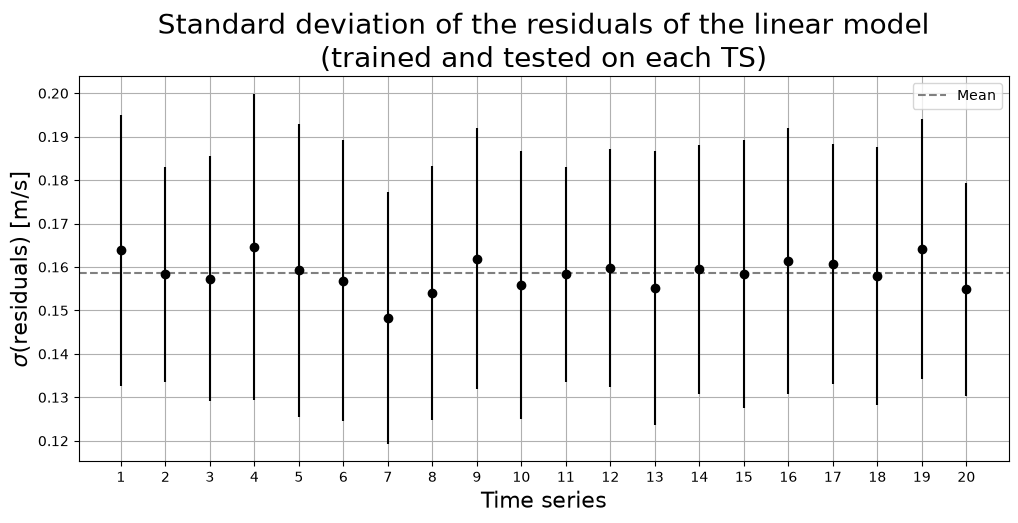

In [24]:
# show std for each TS
ts_arr = np.linspace(1, N_files, N_files)  # array of integers from 1 to the number of TS (+1 to account for splitting the first TS)
y = np.mean(res_sigma, axis=1)
y_err = np.std(res_sigma, axis=1)

# plot
fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title(f'Standard deviation of the residuals of the linear model\n(trained and tested on each TS)', size=20)

ax.grid()
ax.errorbar(ts_arr, y, y_err, fmt='o', color='k', zorder=2)
ax.axhline(np.mean(y), color='gray', linestyle='--', label='Mean', zorder=1)

ax.set_xlabel('Time series', size=16)
ax.set_ylabel(r'$\sigma$(residuals) [m/s]', size=16)

ax.set_xticks(ts_arr)

ax.legend()
plt.show()

In [25]:
# overall sigma_res
print(f'The mean of Sigma(res) over all TS is {np.mean(y):.3f} +- {np.std(y):.3f} m/s.')
print(f'The mean of the error bars is {np.mean(y_err):.3f} m/s.')

The mean of Sigma(res) over all TS is 0.159 +- 0.004 m/s.
The mean of the error bars is 0.030 m/s.


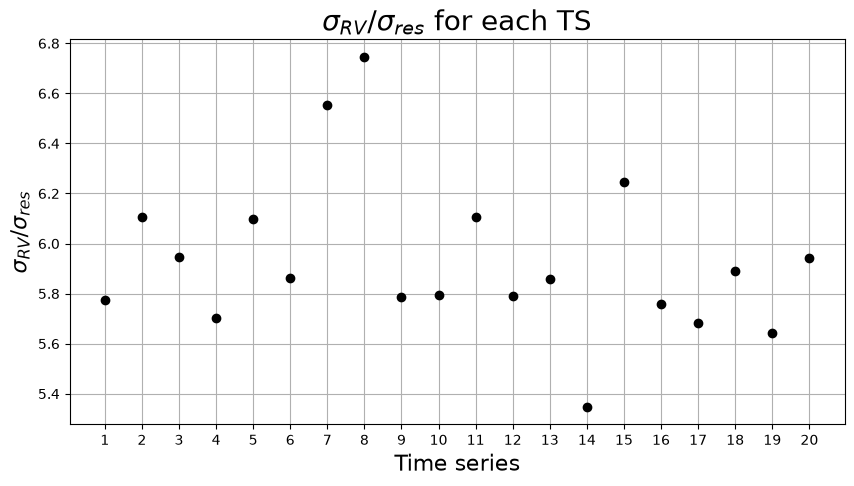

In [26]:
# sigma(RV) / sigma(residuals)
sigma_rv = np.std(rv_tm, axis=1)  # standard deviation of the RVs of each TS
sigma_ratio = sigma_rv / np.mean(res_sigma, axis=1)

fig, ax = plt.subplots(figsize=(10, 5))

ax.set_title(r'$\sigma_{RV} / \sigma_{res}$ for each TS', size=20)

ax.grid()
ax.scatter(ts_arr, sigma_ratio, color='k', zorder=2)

ax.set_xlabel('Time series', size=16)
ax.set_ylabel(r'$\sigma_{RV} / \sigma_{res}$', size=16)
ax.set_xticks(ts_arr)

plt.show()